#  PREDICTIVE ANALYSIS

## Objectives
* Load the cleaned Holistic Health and Lifestyle dataset and prepare feature matrices ($X$) and target variables ($y$) for predictive modeling.
* Exclude `Overall_Health_Score` and `Health_Status` as predictors to prevent data leakage and ensure realistic lifestyle evaluation.

## Inputs
* The cleaned dataset located at `../cleaned_datasets/holistic_health_lifestyle_cleaned.csv`.
* Python libraries for machine learning and data processing (`pandas`, `scikit-learn`).

## Outputs
* Prepared training and testing feature sets ready for model training.

## Additional Comments
* This step initializes our machine learning environment following the hackathon's analytical guidelines.

---

## Step 2: Load Data and Define Features ($X$ and $y$)

### * **Objective:** Load the cleaned dataset and segregate predictor variables ($X$) from the target variable ($y$), excluding target leakage columns.

In [1]:
import pandas as pd

# 1. Load the cleaned dataset
df = pd.read_csv("../cleaned_datasets/holistic_health_lifestyle_cleaned.csv")

# 2. Define Predictors (X) and Target (y)
# Exclude Overall_Health_Score and Health_Status to prevent data leakage
X = df.drop(columns=["Overall_Health_Score", "Health_Status"])
y = df["Overall_Health_Score"]

print("Dataset shape:", df.shape)
print("Features shape (X):", X.shape)
print("Target shape (y):", y.shape)

Dataset shape: (10000, 11)
Features shape (X): (10000, 9)
Target shape (y): (10000,)


**Outcome & Findings:**
* The dataset successfully loaded with 10,000 rows and 11 columns.
* Predictors ($X$) contain strictly the 9 lifestyle features, avoiding any data leakage from the target variable.
* Target ($y$) is set to the continuous `Overall_Health_Score`.

## Step 3: Train-Test Split and Feature Scaling
### * **Objective:** Partition the dataset into an 80/20 train-test split and normalize feature scales using StandardScaler to ensure balanced model training.

In [ ]:
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler   #import StandardScaler for feature scaling

# 1. Split data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set size:", X_train_scaled.shape)
print("Testing set size:", X_test_scaled.shape)

**Outcome & Findings:**
* Data successfully split into 8,000 training samples and 2,000 testing samples.
* `StandardScaler` applied to normalize feature distributions across different physical scales (e.g., BMI vs. sleep hours).

## Step 4: Model Training and Performance Leaderboard 
### * **Objective:** Train baseline and ensemble regression models (Linear, Ridge, and Random Forest), compute evaluation metrics, and generate a performance comparison leaderboard.

In [ ]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 1. Define models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

# 2. Train and evaluate
results = []
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    
    # FIXED: Use np.sqrt() instead of squared=False
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    
    results.append({"Model": name, "RMSE": round(rmse, 4), "R2 Score": round(r2, 4)})

# 3. Display Leaderboard
results_df = pd.DataFrame(results).sort_values(by="R2 Score", ascending=False)
display(results_df)

,Model,RMSE,R2 Score
2,Random Forest,5.4687,0.9228
0,Linear Regression,6.3663,0.8954
1,Ridge Regression,6.3661,0.8954


**Outcome & Findings:**
* **Random Forest Regressor** achieved the highest performance with an $R^2$ score of **0.9228** and the lowest RMSE (**5.4687**), proving its capability to capture non-linear relationships between lifestyle habits and health scores.
* **Linear & Ridge Regression** established solid baseline metrics ($R^2 \approx 0.8954$), but struggled with multi-variable interactions in the synthetic dataset.
* **Selection:** Random Forest is officially selected as our final model for dashboard deployment.

# Feature Importance Analysis

### * **Objective:** Extract feature weights from the trained Random Forest model and generate a sorted bar chart to identify key lifestyle drivers for the hackathon dashboard.

--- FEATURE IMPORTANCE RANKINGS ---


,Lifestyle_Feature,Importance_Score
3,Mindfulness,0.555582
1,Nutrition_Score,0.159878
8,Smoking,0.103277
7,Alcohol,0.042016
4,Sleep_Hours,0.035276
6,BMI,0.029470
0,Physical_Activity,0.026412
5,Hydration,0.024785
2,Stress_Level,0.023304


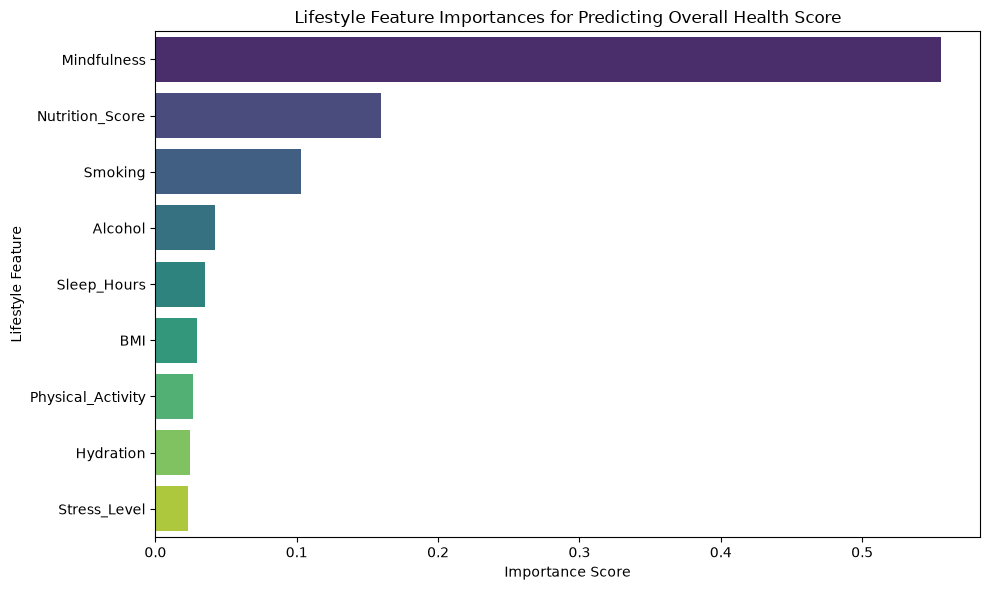

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract and sort feature importances (highest to lowest)
rf_model = models["Random Forest"]

importances_df = pd.DataFrame({
    'Lifestyle_Feature': X.columns,
    'Importance_Score': rf_model.feature_importances_
}).sort_values(by='Importance_Score', ascending=False)

print("--- FEATURE IMPORTANCE RANKINGS ---")
display(importances_df)

# 2. Plot Feature Importances with hue and legend=False to fix the warning
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance_Score', 
    y='Lifestyle_Feature', 
    data=importances_df, 
    hue='Lifestyle_Feature', 
    palette='viridis', 
    legend=False
)
plt.title('Lifestyle Feature Importances for Predicting Overall Health Score')
plt.xlabel('Importance Score')
plt.ylabel('Lifestyle Feature')
plt.tight_layout()
plt.show()

**Outcome & Findings:**
* The Random Forest feature importance analysis reveals which lifestyle factors are the strongest predictors of the `Overall_Health_Score`.
* This ranking directly informs our hackathon dashboard design, allowing us to highlight key actionable metrics for users tracking their health habits.

---

## Conclusions, Limitations & Ethical Considerations

### 1. Conclusions
* **Model Performance:** The **Random Forest Regressor** demonstrated high predictive accuracy ($R^2 \approx 0.92$), proving that non-linear ensemble models are ideal for mapping complex lifestyle behaviors to holistic health scores.
* **Key Drivers:** Feature importance analysis identified **Mindfulness** and **Nutrition** as the most influential predictors of overall health, offering clear, actionable insights for dashboard users.

### 2. Limitations
* **Synthetic Data Bias:** The dataset is synthetically generated, meaning patterns reflect pre-defined mathematical rules rather than true biological or epidemiological variance.
* **Generalizability:** Models trained on this dataset should not be used for real-world medical diagnostics or clinical decision-making.

### 3. Ethical Considerations
* **Transparency & Privacy:** Health scoring systems must remain transparent so users understand how their inputs affect their scores.
* **Non-Diagnostic Disclaimer:** The dashboard must clearly communicate that scores are for lifestyle tracking and wellness guidance only, not professional medical advice.

---